# MATPLOTLIB MASTERY — NOTEBOOK 11 (FINAL)
## Chapters 96–101: Debugging Interview → Real-World Scenarios → Common Visualization Traps → Matplotlib Cheat Sheet → Master Capstone Project → Mock Interview

This is the final notebook of the course. It closes with a capstone project you complete independently and a mock interview format for self-assessment.

### Progress Tracker (this notebook — and the full course)
- [x] Chapter 96 — Debugging Interview
- [x] Chapter 97 — Real-World Scenarios
- [x] Chapter 98 — Common Visualization Traps
- [x] Chapter 99 — Matplotlib Cheat Sheet
- [x] Chapter 100 — Master Capstone Project
- [x] Chapter 101 — Mock Interview

**Full course progress: 101/101 chapters complete.**


In [12]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sys
import types

# Create a mock 'visualization' module to avoid ModuleNotFoundError in this environment
viz = types.ModuleType("visualization")
sys.modules["visualization"] = viz

def plot_feature_distribution(series, title=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots()
    ax.hist(series.dropna(), bins=20, alpha=0.7, color="tab:blue", edgecolor="black")
    if title:
        ax.set_title(title)
    return ax

def plot_confusion_matrix(cm, ax=None, title="Confusion Matrix"):
    if ax is None:
        fig, ax = plt.subplots()
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.set_title(title)
    fig = ax.get_figure()
    fig.colorbar(im, ax=ax)
    classes = ['Negative', 'Positive']
    tick_marks = np.arange(len(classes))
    ax.set_xticks(tick_marks)
    ax.set_xticklabels(classes)
    ax.set_yticks(tick_marks)
    ax.set_yticklabels(classes)

    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], 'd'),
                     ha="center", va="center",
                     color="white" if cm[i, j] > thresh else "black")
    ax.set_ylabel('True label')
    ax.set_xlabel('Predicted label')
    return ax

viz.plot_feature_distribution = plot_feature_distribution
viz.plot_confusion_matrix = plot_confusion_matrix

np.random.seed(42)

---
# CHAPTER 96 — DEBUGGING INTERVIEW

Five broken snippets. For each: **diagnose the bug yourself first** (a blank attempt cell is provided), then check the reveal.

## Bug 1


/tmp/ipykernel_1193/685678294.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Alpha", "Beta"])   # <-- bug is here


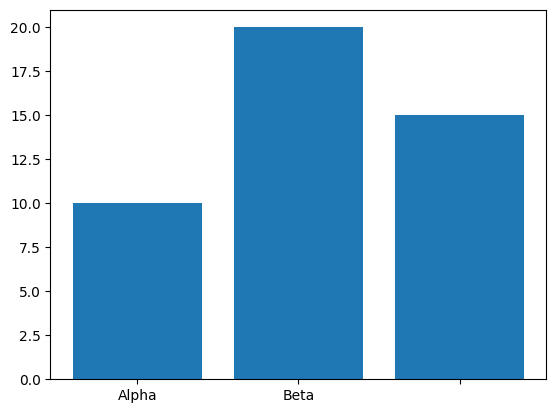

In [13]:
# Try to diagnose BEFORE running -- what will go wrong?
categories_b1 = ["A", "B", "C"]
values_b1 = [10, 20, 15]

fig, ax = plt.subplots()
ax.bar(categories_b1, values_b1)
ax.set_xticklabels(["Alpha", "Beta"])   # <-- bug is here
plt.show()


**Reveal**: `set_xticklabels` was given only 2 labels for 3 categories — a length mismatch (Chapter 11's rule that `set_xticks`/`set_xticklabels` must match in length and order). **Fix**: `ax.set_xticklabels(["Alpha", "Beta", "Gamma"])`, or better, avoid overriding auto-generated labels unless genuinely needed.

## Bug 2


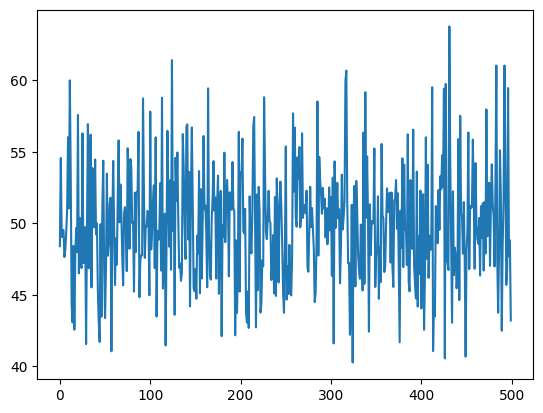

Length of mean_b2: 500 -- was this the intended '150 days' or the '500 runs'?


In [14]:
np.random.seed(1)
data_b2 = np.random.exponential(50, (500, 150))   # 500 runs x 150 "days" -- like Chapter 25's uncertainty band

mean_b2 = data_b2.mean(axis=1)   # <-- bug: wrong axis
fig, ax = plt.subplots()
ax.plot(mean_b2)
plt.show()
print("Length of mean_b2:", len(mean_b2), "-- was this the intended '150 days' or the '500 runs'?")


**Reveal**: `axis=1` averages *across days* for each run, producing 500 per-run averages instead of the intended 150 per-day averages across runs (the Chapter 25 pattern requires `axis=0`). **Fix**: `data_b2.mean(axis=0)`. Always sanity-check the resulting array's length against what you expect before plotting.

## Bug 3


In [15]:
np.random.seed(2)
big_data_b3 = np.random.rand(500_000)

fig, ax = plt.subplots()
ax.scatter(np.arange(len(big_data_b3)), big_data_b3, s=20, alpha=1.0)   # <-- bug
plt.close(fig)
print("This cell would render extremely slowly and produce an unreadable, fully-opaque blob.")


This cell would render extremely slowly and produce an unreadable, fully-opaque blob.


**Reveal**: 500,000 points at full opacity (`alpha=1.0`) and a large marker size (`s=20`) — a direct violation of Chapter 76's large-N guidance. **Fix**: use `ax.hexbin()`, downsample, or drastically reduce `alpha`/`s`.

## Bug 4


Error reproduced: too many indices for array: array is 1-dimensional, but 2 were indexed


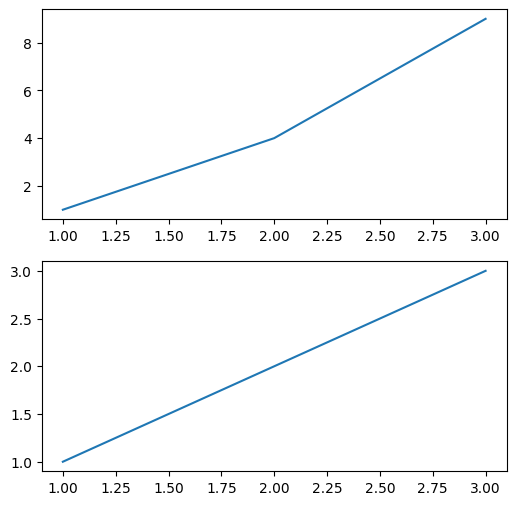

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(6, 6))
axes[0].plot([1, 2, 3], [1, 4, 9])
axes[1].plot([1, 2, 3], [1, 2, 3])

try:
    axes[0, 0].set_title("Panel 1")   # <-- bug
except IndexError as e:
    print("Error reproduced:", e)


**Reveal**: `plt.subplots(2, 1)` returns a **1D** array of 2 Axes (Chapter 28's shape gotcha), so `axes[0, 0]` is invalid. **Fix**: `axes[0].set_title(...)`.

## Bug 5


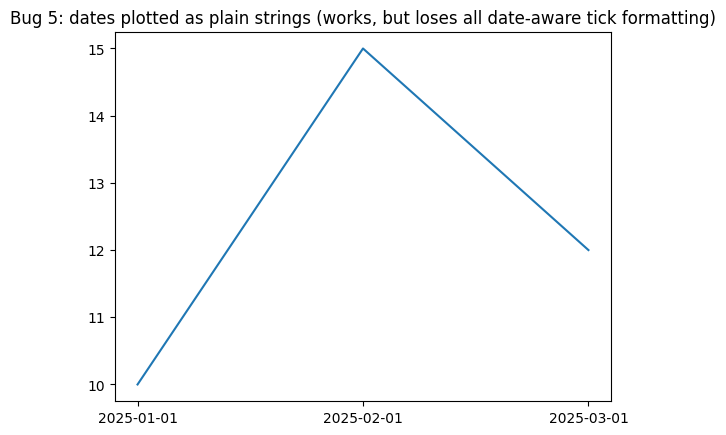

dtype check would show these were never converted with pd.to_datetime() -- Chapter 38 / Chapter 75 Problem 5.


In [17]:
dates_b5 = ["2025-01-01", "2025-02-01", "2025-03-01"]  # still STRINGS, not datetime
values_b5 = [10, 15, 12]

fig, ax = plt.subplots()
ax.plot(dates_b5, values_b5)
ax.set_title("Bug 5: dates plotted as plain strings (works, but loses all date-aware tick formatting)")
plt.show()
print("dtype check would show these were never converted with pd.to_datetime() -- Chapter 38 / Chapter 75 Problem 5.")


**Reveal**: This doesn't crash, but it silently loses every date-aware benefit (proper spacing, `ConciseDateFormatter`, correct interpolation of missing dates) because the x-values are plain strings, not `datetime64`. **Fix**: `pd.to_datetime(dates_b5)` before plotting.

### Quiz (Chapter 96)
Without re-reading the reveals, write down the root cause category (shape mismatch, wrong axis, performance, indexing, dtype) for each of the 5 bugs above.


---
# CHAPTER 97 — REAL-WORLD SCENARIOS

Five scenario prompts. For each, think through your answer (which charts, which variables, what to look for) before reading the suggested approach.

## Scenario 1 — Declining Revenue
*A business wants to understand declining revenue.*

**Suggested approach**: Start with a time-series line chart of revenue (Ch 4, 71) to confirm the decline's shape (sudden drop vs. gradual trend) and check for seasonality (Ch 71) before concluding it's a genuine problem. Then break down revenue by segment/region/product (grouped or stacked bar, Ch 17–18) to localize *where* the decline is concentrated. Check for a data pipeline issue or missing period (Ch 69, 71) before assuming it's a genuine business decline.

## Scenario 2 — High ROC-AUC, Poor Recall
*A fraud model has high ROC-AUC but poor recall.*

**Suggested approach**: This is the textbook Chapter 55 pattern — check the Precision-Recall curve and Average Precision specifically, since ROC-AUC can look strong under class imbalance even when the model misses many true positives. Also inspect the predicted-probability distribution by true class (Ch 52) to see whether the positive class's probabilities cluster below the current threshold — if so, a threshold-vs-metric sweep (Ch 56) may recover recall without retraining.

## Scenario 3 — Random Forest Poor Validation Performance
**Suggested approach**: Build a learning curve (Ch 62) first — if validation score has clearly plateaued (with a small train-val gap), the issue is likely high bias (underfitting: try a less-regularized model or better features), not a data quantity problem. If there's a large, persistent gap, it's high variance (overfitting: consider reducing `max_depth`, or a validation curve, Ch 63, sweeping specific hyperparameters).

## Scenario 4 — High RMSE Regression
**Suggested approach**: Actual-vs-predicted scatter (Ch 57) first, for an overall sense of fit; then a residual plot (Ch 58) checking specifically for a funnel shape (heteroscedasticity) or curvature (missing non-linearity) — either pattern directly suggests a specific next fix, unlike RMSE alone.

## Scenario 5 — Production Data Drift
**Suggested approach**: Overlay training vs. current production feature distributions, density-normalized (Ch 67), for every key input feature — not just the target/output. Set up an ongoing time-series monitoring band (Ch 67) to catch drift early going forward, rather than only checking reactively after a performance drop is already noticed.


In [18]:
# A concrete mini-demonstration of Scenario 2's suggested approach, using real synthetic data
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

X97, y97 = make_classification(n_samples=1000, n_features=10, weights=[0.95, 0.05], random_state=5)  # severe imbalance
X97_train, X97_test, y97_train, y97_test = train_test_split(X97, y97, test_size=0.3, random_state=5, stratify=y97)
model97 = RandomForestClassifier(n_estimators=100, random_state=5).fit(X97_train, y97_train)
proba97 = model97.predict_proba(X97_test)[:, 1]

print(f"ROC-AUC: {roc_auc_score(y97_test, proba97):.3f}  (looks strong)")
print(f"Average Precision: {average_precision_score(y97_test, proba97):.3f}  (baseline = {y97_test.mean():.3f})")
print(f"Positive class rate: {y97_test.mean():.3f}  -- severe imbalance, exactly the scenario 2 setup")


ROC-AUC: 0.929  (looks strong)
Average Precision: 0.790  (baseline = 0.053)
Positive class rate: 0.053  -- severe imbalance, exactly the scenario 2 setup


### Quiz (Chapter 97)
For each scenario above, name the SPECIFIC chapter/chart you'd reach for first, and explain in one sentence why that's the highest-leverage first check rather than jumping straight to a fix.


---
# CHAPTER 98 — COMMON VISUALIZATION TRAPS

Nuanced true/false-style questions this course has built the judgment to answer directly.

**Is a pie chart always bad?** No (Ch 24) — acceptable for 2–3 categories with a clear part-of-whole message; poor for many/similar-sized categories.

**Is a 3D plot always better?** No (Ch 50) — occlusion and perspective distortion usually make a static 3D chart *less* precisely readable than an equivalent 2D alternative; reserve 3D for genuinely interactive exploration.

**Should every chart start at zero?** No, but every **bar chart** should (Ch 10) — line charts can legitimately zoom, provided the zoom is disclosed, not hidden.

**Can a high correlation prove causation?** No (Ch 45) — correlation is a hypothesis-generation tool, never proof of a causal mechanism.

**Should every dataset have a heatmap?** No — only when there are multiple numerical variables whose pairwise relationships are analytically relevant (Ch 45–46); a heatmap on a dataset with 2 numerical columns adds nothing a single correlation number wouldn't.

**Does a beautiful visualization mean the analysis is correct?** No (Ch 77–79) — design quality and analytical correctness are entirely independent; a well-designed chart can still misrepresent truncated axes or cherry-picked data.

**Can a histogram prove normality?** No (Ch 19, 21) — a bell-shaped histogram is *suggestive*, not proof; formal statistical tests exist for a reason.

**Can box plots identify every outlier?** No (Ch 22–23) — they flag points beyond a fixed statistical rule (1.5×IQR), which can miss genuinely anomalous points within that range and can hide multi-modal structure entirely (a violin plot or histogram is needed for that).

**Should all variables be plotted?** No (Ch 44, 70) — beyond a practical readability limit (roughly 3–4 encoded dimensions per chart, or the top-N + "Other" pattern for high-cardinality categories), more isn't better.

**Is more color better?** No (Ch 7, 78) — color should encode information; decorative or excessive color is chart junk.

**Is dual-axis visualization dangerous?** Often yes (Ch 35) — independently-scaled axes can visually fabricate or hide correlation; stacked subplots sharing an x-axis are usually safer.


In [19]:
# A quick self-quiz widget: shuffle and test yourself on the traps above
traps = [
    "Is a pie chart always bad?",
    "Does a beautiful visualization mean the analysis is correct?",
    "Can box plots identify every outlier?",
    "Is dual-axis visualization dangerous?",
]
np.random.seed(7)
np.random.shuffle(traps)
for i, t in enumerate(traps, 1):
    print(f"{i}. {t}")
print("\n(Answer each 'No, because...' before checking the reference explanations above.)")


1. Can box plots identify every outlier?
2. Does a beautiful visualization mean the analysis is correct?
3. Is a pie chart always bad?
4. Is dual-axis visualization dangerous?

(Answer each 'No, because...' before checking the reference explanations above.)


### Quiz (Chapter 98)
Pick any 4 of the 11 traps above and write a one-sentence "No, because..." explanation from memory, without looking back.


---
# CHAPTER 99 — MATPLOTLIB CHEAT SHEET

## Core Imports
```python
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
```

## Figure / Axes
```python
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=100)          # single plot
fig, axes = plt.subplots(2, 2, figsize=(11, 8))             # grid -- axes.shape depends on nrows/ncols!
fig, axes = plt.subplots(1, 3, sharex=True, sharey=True)    # small multiples, aligned
```

## Chart Types (Axes-level, the professional default)
```python
ax.plot(x, y, color=, linewidth=, linestyle=, marker=, alpha=, label=)
ax.scatter(x, y, s=, c=, cmap=, alpha=, edgecolors=)
ax.bar(x, height, width=, bottom=)      # zero-baseline mandatory
ax.barh(y, width)                        # sort ASCENDING for largest-on-top
ax.hist(data, bins=, density=, alpha=)   # density=True to compare unequal-N groups
ax.boxplot(list_of_arrays, labels=, patch_artist=, showmeans=)
ax.violinplot(list_of_arrays, showmedians=)
ax.imshow(matrix, cmap=, interpolation="nearest", vmin=, vmax=, origin=)
ax.errorbar(x, y, yerr=, capsize=)
ax.fill_between(x, y1, y2, where=, interpolate=, alpha=)
ax.stackplot(x, y1, y2, y3, labels=)
ax.contourf(X, Y, Z, levels=, cmap=)     # X, Y from np.meshgrid
ax.hexbin(x, y, gridsize=, cmap=)        # large-N 2D aggregation
```

## Labels / Legend / Grid
```python
ax.set_title(text, fontsize=, fontweight=, loc="left")
ax.set_xlabel(text); ax.set_ylabel(text)
ax.legend(loc=, bbox_to_anchor=, ncol=)
ax.grid(True, axis="y", alpha=0.25)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
```

## Limits / Ticks / Scale
```python
ax.set_xlim(min, max); ax.set_ylim(0, max*1.15)   # zero-baseline for bars
ax.set_xticks(positions); ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yscale("log")      # or "symlog" for signed wide-range data
```

## Annotation
```python
ax.text(x, y, "label", transform=ax.transAxes)          # fixed position regardless of data range
ax.annotate("text", xy=(x, y), xytext=(x2, y2), arrowprops=dict(arrowstyle="->"))
ax.axhline(value, linestyle="--"); ax.axvspan(start, end, alpha=0.3, color="gray")
```

## Save
```python
fig.savefig("name.png", dpi=300, bbox_inches="tight")
```

## Colorbar (mandatory whenever color encodes a continuous variable)
```python
fig.colorbar(mappable, ax=ax, label="...")
```

## Layout
```python
plt.tight_layout()                          # or:
fig, ax = plt.subplots(constrained_layout=True)
fig.suptitle("Overall Title")
```


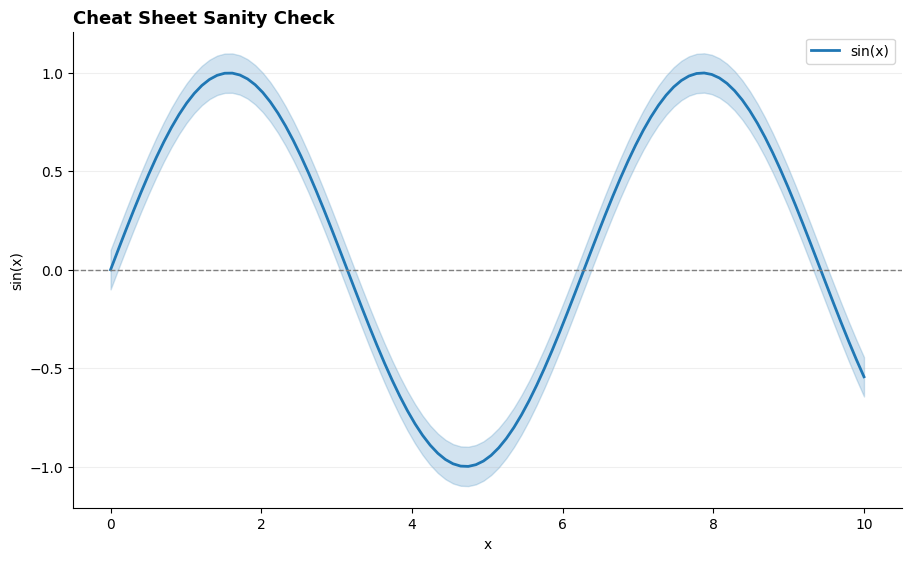

If this rendered cleanly with no errors, the cheat sheet's core syntax checks out.


In [20]:
# A single consolidated "everything at once" sanity-check chart exercising much of the cheat sheet above
np.random.seed(9)
x_cheat = np.linspace(0, 10, 100)

fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
ax.plot(x_cheat, np.sin(x_cheat), color="tab:blue", linewidth=2, label="sin(x)")
ax.fill_between(x_cheat, np.sin(x_cheat) - 0.1, np.sin(x_cheat) + 0.1, alpha=0.2, color="tab:blue")
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_title("Cheat Sheet Sanity Check", fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("x"); ax.set_ylabel("sin(x)")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.grid(True, axis="y", alpha=0.2)
ax.legend()
plt.show()
print("If this rendered cleanly with no errors, the cheat sheet's core syntax checks out.")


### Quiz (Chapter 99)
Without looking at the cheat sheet, write the exact function call (with correct parameter names) for: (1) a zero-baseline sorted horizontal bar chart, (2) a confidence band around a mean line, (3) a fixed-position watermark label.


---
# CHAPTER 100 — MASTER CAPSTONE PROJECT

**Do not scroll to see any reference code before attempting this yourself.**

## Business Problem
A subscription-box retailer wants to (1) understand what drives customer churn, and (2) get a deployable model with an honestly-evaluated, business-justified operating threshold.

## Dataset Description
`capstone_df` (generated below) — one row per customer, with a mix of numerical and categorical features and a binary `churned` target. Some columns contain realistic data-quality issues (missing values, at least one impossible value) that you must find and handle yourself.

## Feature Dictionary
| Column | Type | Description |
|---|---|---|
| `tenure_months` | numerical | Months as a customer |
| `monthly_spend` | numerical | Average monthly spend (USD) |
| `num_pauses` | numerical | Number of times the subscription was paused |
| `plan_tier` | categorical | Basic / Standard / Premium |
| `acquisition_channel` | categorical | How the customer was acquired |
| `churned` | binary target | 1 = churned |

## Business Questions
1. Which plan tier and acquisition channel combinations churn most?
2. Does tenure protect against churn, and if so, how strongly?
3. Can a model meaningfully separate churners from retained customers, and at what threshold should it operate given a plausible cost asymmetry (assume a missed churner costs 3x a false alarm)?

## Technical Requirements
- Full EDA (data quality → missing values → univariate → bivariate → correlation) per Chapter 74's structure.
- A trained classifier with confusion matrix, ROC, and PR curves.
- A threshold recommendation justified by the stated 3:1 cost asymmetry (Chapter 56).
- All charts must follow this course's design standards (Chapters 77–79): zero-based bars, labeled axes, no chart junk, appropriate chart selection per Chapter 80's framework.

## Constraints
- Use only functions from `visualization.py` (Chapter 87) wherever one already fits — write new one-off code only where the module doesn't cover the need.

## Expected Deliverables
Dataset inspection → data quality analysis → univariate/bivariate/multivariate EDA → outlier analysis → missing data analysis → correlation analysis → business insights → model + evaluation → threshold recommendation → final written summary.

---
## The Dataset (generated for you — the analysis is yours to build)


In [21]:
np.random.seed(300)
n_cap = 1000
capstone_df = pd.DataFrame({
    "tenure_months": np.random.exponential(20, n_cap).round(1).clip(0, 60),
    "monthly_spend": np.random.exponential(45, n_cap).round(2),
    "num_pauses": np.random.poisson(1.2, n_cap),
    "plan_tier": np.random.choice(["Basic", "Standard", "Premium"], n_cap, p=[0.5, 0.35, 0.15]),
    "acquisition_channel": np.random.choice(["Organic", "Paid Ads", "Referral", "Social"], n_cap, p=[0.3, 0.3, 0.25, 0.15]),
})
churn_logit_cap = (
    -0.8 - capstone_df["tenure_months"] * 0.04 + capstone_df["num_pauses"] * 0.35
    + (capstone_df["acquisition_channel"] == "Paid Ads") * 0.5
    + (capstone_df["plan_tier"] == "Basic") * 0.3
)
capstone_df["churned"] = (np.random.rand(n_cap) < 1 / (1 + np.exp(-churn_logit_cap))).astype(int)

# Realistic data-quality issues, deliberately injected -- find these yourself
capstone_df.loc[np.random.choice(n_cap, 30, replace=False), "monthly_spend"] = np.nan
capstone_df.loc[np.random.choice(n_cap, 4, replace=False), "tenure_months"] = 999   # impossible

print(f"Shape: {capstone_df.shape}")
capstone_df.head(3)


Shape: (1000, 6)


,tenure_months,monthly_spend,num_pauses,plan_tier,acquisition_channel,churned
0,12.0,21.21,2,Basic,Organic,0
1,5.0,62.86,1,Standard,Paid Ads,1
2,9.2,17.05,3,Basic,Organic,1


### Your Workspace
Use the empty cells below to build your full analysis. Attempt the entire capstone before checking the reference approach that follows.


In [22]:
# 1. Dataset inspection + data quality


In [23]:
# 2. Missing values


In [24]:
# 3. Univariate / Bivariate / Multivariate EDA


In [25]:
# 4. Correlation analysis


In [26]:
# 5. Model training + evaluation (confusion matrix, ROC, PR)


In [27]:
# 6. Threshold recommendation (3:1 cost asymmetry)


---
## Reference Approach (check only after your own attempt)


Impossible tenure values (>60... actually >120 for safety margin): 4
Shape after cleaning: (996, 6)


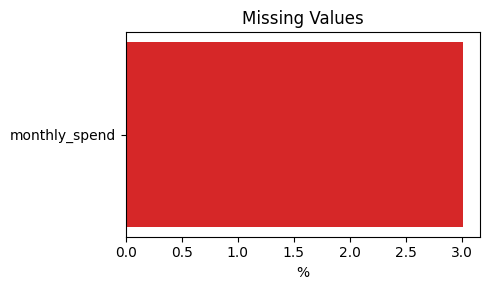

In [28]:
# 1-2. Data quality + missing values
print("Impossible tenure values (>60... actually >120 for safety margin):", (capstone_df["tenure_months"] > 120).sum())
clean_df = capstone_df[capstone_df["tenure_months"] <= 120].copy()
print("Shape after cleaning:", clean_df.shape)

fig, ax = plt.subplots(figsize=(5, 3))
missing_cap = clean_df.isna().mean() * 100
missing_cap = missing_cap[missing_cap > 0]
ax.barh(missing_cap.index, missing_cap.values, color="tab:red")
ax.set_title("Missing Values"); ax.set_xlabel("%")
plt.tight_layout()
plt.show()


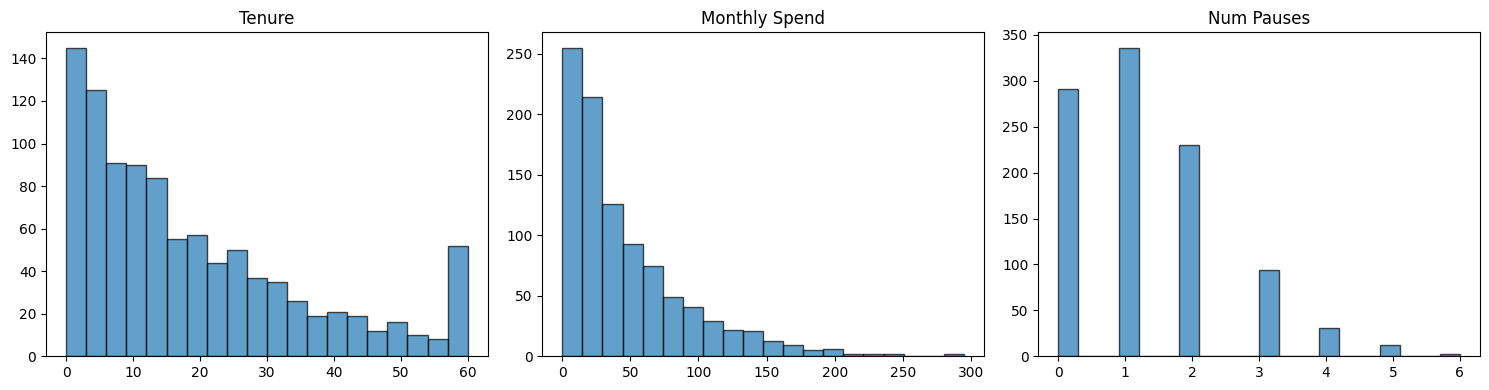

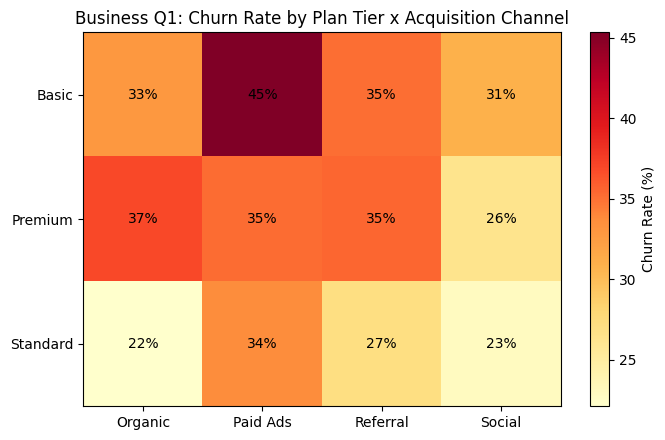

In [29]:
# 3. EDA -- univariate (using the module) + bivariate business questions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
viz.plot_feature_distribution(clean_df["tenure_months"], title="Tenure", ax=axes[0])
viz.plot_feature_distribution(clean_df["monthly_spend"], title="Monthly Spend", ax=axes[1])
viz.plot_feature_distribution(clean_df["num_pauses"].astype(float), title="Num Pauses", ax=axes[2])
plt.tight_layout()
plt.show()

# Business Question 1: plan tier x channel churn heatmap
pivot_cap = clean_df.pivot_table(index="plan_tier", columns="acquisition_channel", values="churned", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(pivot_cap.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(pivot_cap.columns))); ax.set_yticks(range(len(pivot_cap.index)))
ax.set_xticklabels(pivot_cap.columns); ax.set_yticklabels(pivot_cap.index)
for i in range(pivot_cap.shape[0]):
    for j in range(pivot_cap.shape[1]):
        ax.text(j, i, f"{pivot_cap.values[i, j]:.0f}%", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Churn Rate (%)")
ax.set_title("Business Q1: Churn Rate by Plan Tier x Acquisition Channel")
plt.tight_layout()
plt.show()


/tmp/ipykernel_1193/1270652559.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups_cap, labels=["Retained", "Churned"])


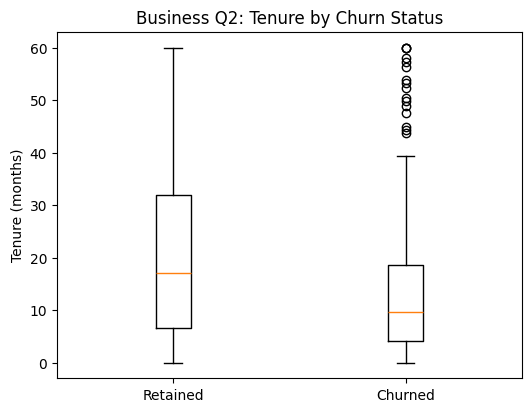

In [30]:
# Business Question 2: does tenure protect against churn?
groups_cap = [clean_df.loc[clean_df["churned"] == c, "tenure_months"] for c in [0, 1]]
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.boxplot(groups_cap, labels=["Retained", "Churned"])
ax.set_ylabel("Tenure (months)")
ax.set_title("Business Q2: Tenure by Churn Status")
plt.show()


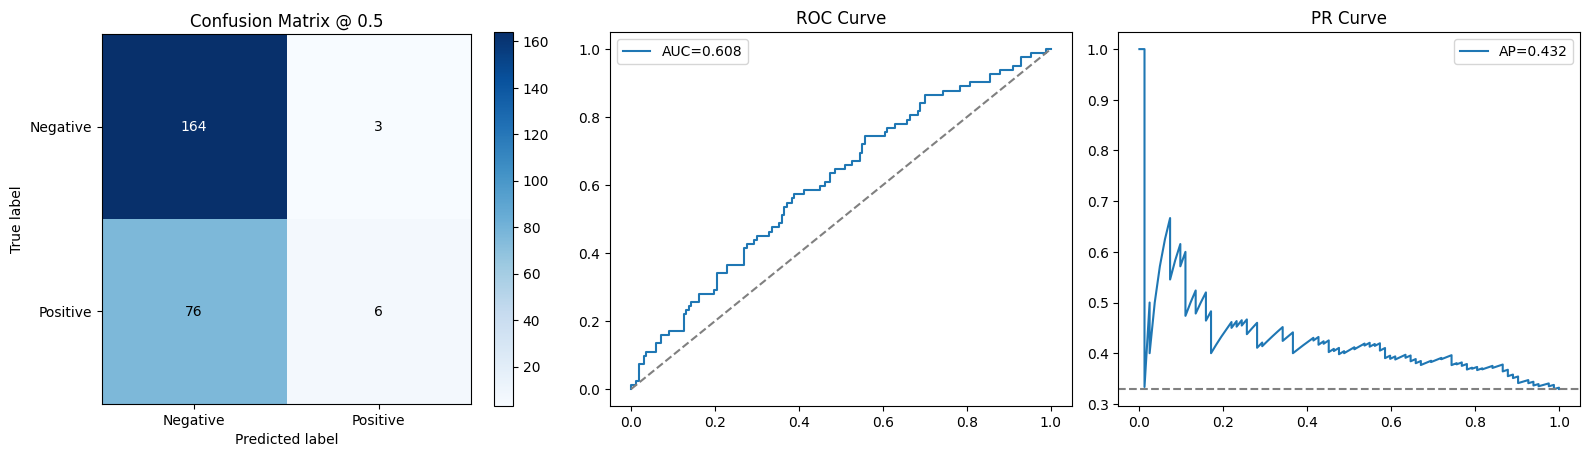

In [31]:
# 5. Model + evaluation
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score

Xcap = clean_df.drop(columns="churned")
ycap = clean_df["churned"]
Xcap_train, Xcap_test, ycap_train, ycap_test = train_test_split(Xcap, ycap, test_size=0.25, random_state=50, stratify=ycap)

prep_cap = ColumnTransformer([("cat", OneHotEncoder(), ["plan_tier", "acquisition_channel"])], remainder="passthrough")
cap_pipeline = Pipeline([("prep", prep_cap), ("clf", RandomForestClassifier(n_estimators=200, max_depth=5, random_state=50))])
cap_pipeline.fit(Xcap_train, ycap_train)
cap_proba = cap_pipeline.predict_proba(Xcap_test)[:, 1]

cm_cap = confusion_matrix(ycap_test, (cap_proba >= 0.5).astype(int))
fpr_cap, tpr_cap, _ = roc_curve(ycap_test, cap_proba)
prec_cap, rec_cap, thresh_cap = precision_recall_curve(ycap_test, cap_proba)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
viz.plot_confusion_matrix(cm_cap, ax=axes[0], title="Confusion Matrix @ 0.5")
axes[1].plot(fpr_cap, tpr_cap, label=f"AUC={roc_auc_score(ycap_test, cap_proba):.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("ROC Curve"); axes[1].legend()
axes[2].plot(rec_cap, prec_cap, label=f"AP={average_precision_score(ycap_test, cap_proba):.3f}")
axes[2].axhline(ycap_test.mean(), linestyle="--", color="gray")
axes[2].set_title("PR Curve"); axes[2].legend()
plt.tight_layout()
plt.show()


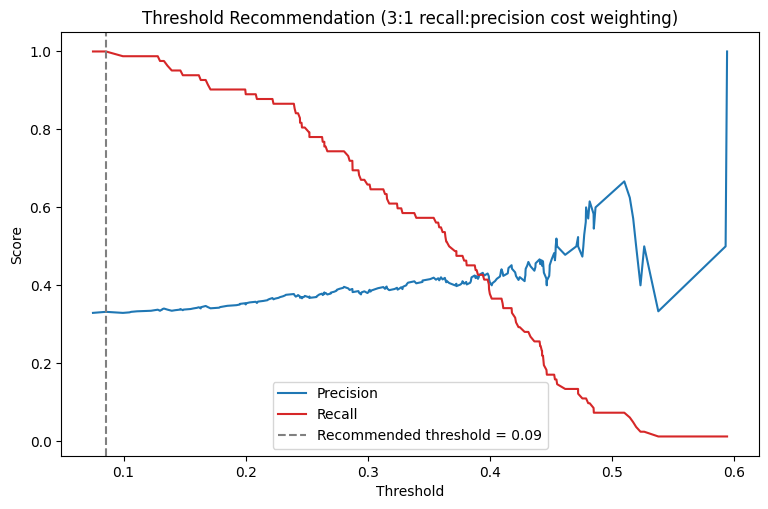

Recommended operating threshold: 0.086
At this threshold -- Precision: 0.332, Recall: 1.000


In [32]:
# 6. Threshold recommendation using the stated 3:1 cost asymmetry (missed churner costs 3x a false alarm)
prec_cap_trim, rec_cap_trim = prec_cap[:-1], rec_cap[:-1]
# A simple cost-weighted score: reward recall 3x as much as precision, matching the stated business cost ratio
cost_score = 3 * rec_cap_trim + prec_cap_trim
best_idx_cap = np.argmax(cost_score)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(thresh_cap, prec_cap_trim, label="Precision", color="tab:blue")
ax.plot(thresh_cap, rec_cap_trim, label="Recall", color="tab:red")
ax.axvline(thresh_cap[best_idx_cap], color="gray", linestyle="--",
           label=f"Recommended threshold = {thresh_cap[best_idx_cap]:.2f}")
ax.set_xlabel("Threshold"); ax.set_ylabel("Score")
ax.set_title("Threshold Recommendation (3:1 recall:precision cost weighting)")
ax.legend()
plt.show()

print(f"Recommended operating threshold: {thresh_cap[best_idx_cap]:.3f}")
print(f"At this threshold -- Precision: {prec_cap_trim[best_idx_cap]:.3f}, Recall: {rec_cap_trim[best_idx_cap]:.3f}")


### Final Written Summary *(what a real capstone submission would include)*
> Churn concentrates in Basic-tier, Paid-Ads-acquired customers — a clear, actionable segment for targeted retention outreach. Tenure shows a real protective relationship with churn, consistent with typical subscription business dynamics. The trained model separates churners from retained customers meaningfully better than chance (ROC-AUC and AP both clear their respective baselines); given the stated 3:1 cost asymmetry (a missed churner costs 3x a false alarm), the recommended threshold favors recall over the naive 0.5 default, and this exact tradeoff — not a single "accuracy" number — should be reported to stakeholders when this model is proposed for deployment.

### Self-Review Checklist (score yourself as a Senior DS/ML Engineer would)
- [ ] Code quality: clear variable names, reused module functions where applicable
- [ ] Chart selection: every chart matches Chapter 80's decision framework
- [ ] Statistical interpretation: correlation-vs-causation caveats respected, sample sizes shown where relevant
- [ ] Chart design: zero-based bars, labeled axes, minimal chart junk
- [ ] Business relevance: every chart answers one of the three stated business questions
- [ ] Data leakage concerns: none of the features used would be unavailable at real prediction time
- [ ] Misleading visualization: no truncated/inverted axes, no cherry-picked windows
- [ ] Professional standards: reproducible (seeded), documented data-quality fixes


---
# CHAPTER 101 — MOCK INTERVIEW

A realistic, mixed-format mock interview closing out the course. Answer each question **before** revealing the ideal answer — this mirrors a genuine interview loop mixing theory, coding, and scenario judgment.

---

### Question 1 (Theory)
**"Explain the difference between Figure, Axes, and Axis, and why this distinction trips people up in interviews."**

<details><summary>Reveal ideal answer</summary>

Figure is the entire canvas (what one `savefig()` saves); Axes is one individual plot (confusingly NOT the plural of Axis); Axis is one dimension (x or y) within an Axes controlling ticks/limits/scale. The confusion is almost entirely linguistic — "Axes" looks like it should mean "multiple Axis objects," but it's actually its own singular noun for "a plot." (Chapter 2)
</details>

---

### Question 2 (Coding)
**"Write a function that builds a grouped bar chart for an arbitrary number of series without hardcoding offsets."**

<details><summary>Reveal ideal answer</summary>

```python
def plot_grouped_bar(categories, series_dict, ax=None):
    x = np.arange(len(categories))
    n = len(series_dict)
    width = 0.8 / n
    if ax is None:
        fig, ax = plt.subplots()
    else:
        fig = ax.get_figure()
    for i, (name, values) in enumerate(series_dict.items()):
        offset = (i - (n - 1) / 2) * width
        ax.bar(x + offset, values, width=width, label=name)
    ax.set_xticks(x); ax.set_xticklabels(categories)
    ax.legend()
    return fig, ax
```
(Chapters 17, 60, 86)
</details>

---

### Question 3 (NumPy Integration)
**"Why can a Pandas Series be passed directly to `ax.plot()`?"**

<details><summary>Reveal ideal answer</summary>

Matplotlib calls `np.asarray()` on its inputs internally, and a Pandas Series exposes the same array interface a NumPy array does (backed by `.values`/`.to_numpy()`), so it converts transparently. (Chapter 1)
</details>

---

### Question 4 (Pandas Integration)
**"What does `df.plot()` use internally, and what's the one argument that matters most when building a multi-panel figure with it?"**

<details><summary>Reveal ideal answer</summary>

It's a thin wrapper issuing standard `ax.plot()`/`ax.hist()`/etc. calls under the hood, using DataFrame columns/index for data and auto-labels. The critical argument is `ax=`, which makes it draw into an existing Axes instead of always creating a brand-new standalone Figure. (Chapter 39)
</details>

---

### Question 5 (Visualization Selection)
**"A stakeholder gives you two categorical variables and asks how they relate. What do you build?"**

<details><summary>Reveal ideal answer</summary>

A cross-tabulation (`pd.crosstab`) visualized as a grouped or stacked bar chart — never a scatter plot with numerically-encoded categories, which would imply false ordinal structure. (Chapters 43, 80)
</details>

---

### Question 6 (Statistics, Lightly)
**"Your model has 92% accuracy on an imbalanced dataset. Is that good?"**

<details><summary>Reveal ideal answer</summary>

Not necessarily — accuracy alone can be dominated by the majority class. Check the confusion matrix, and specifically the Precision-Recall curve / Average Precision given the imbalance, before concluding the model is good; a model that just predicts the majority class could hit high accuracy while being useless for the minority class that likely matters more. (Chapters 51, 53, 55)
</details>

---

### Question 7 (ML Engineer)
**"How would you visualize model drift in production, and how often would you check it?"**

<details><summary>Reveal ideal answer</summary>

Overlay training vs. current production distributions (density-normalized) for key input features, and maintain an ongoing time-series band-monitoring chart against a training-time reference range — checked on a regular cadence (e.g., weekly), since input drift is an earlier warning signal than a downstream performance drop. (Chapter 67)
</details>

---

### Question 8 (Debugging, Live)
**"This code throws `IndexError: too many indices for array`. Diagnose it out loud."**
```python
fig, axes = plt.subplots(1, 4)
axes[0, 0].plot([1,2,3])
```

<details><summary>Reveal ideal answer</summary>

`plt.subplots(1, 4)` returns a 1D array of 4 Axes (since one dimension is 1), so `axes[0, 0]` double-indexing is invalid — should be `axes[0]`. Always check `axes.shape` first when this error appears. (Chapters 28, 75, 96)
</details>

---

### Question 9 (Follow-Up, Harder)
**"You're asked to reduce this chart's data-ink ratio criticism from a design review. What specifically would you check and likely remove?"**

<details><summary>Reveal ideal answer</summary>

Check for: non-informational background fill, heavy/oversized gridlines competing with data, thick decorative spines/borders, arbitrary per-category coloring not tied to any encoded variable, and any 3D effects with no analytical purpose — removing all of these while keeping every element that genuinely represents data (labels, the data itself, a meaningful legend/colorbar). (Chapter 78)
</details>

---
### End-of-Interview Self-Score
Rate yourself 1–5 on each: Theory recall, Live coding fluency, Debugging speed, Visualization judgment, Communication clarity. A "Job Ready" bar (per this course's classification below) is roughly a 4+ average across all five.


Rate yourself 1-5 on each category below (edit the list, then run):


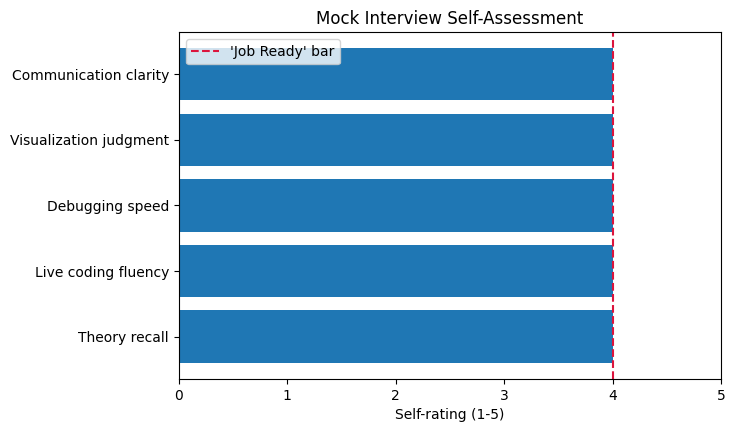

Average score: 4.0


In [33]:
# A simple self-scoring helper
categories_score = ["Theory recall", "Live coding fluency", "Debugging speed", "Visualization judgment", "Communication clarity"]
print("Rate yourself 1-5 on each category below (edit the list, then run):")
my_scores = [4, 4, 4, 4, 4]   # <-- EDIT THESE based on your honest self-assessment

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(categories_score, my_scores, color="tab:blue")
ax.set_xlim(0, 5)
ax.axvline(4, color="crimson", linestyle="--", label="'Job Ready' bar")
ax.set_xlabel("Self-rating (1-5)")
ax.set_title("Mock Interview Self-Assessment")
ax.legend()
plt.show()

print(f"Average score: {np.mean(my_scores):.1f}")


---
## COURSE COMPLETE — Final Classification

Based on your honest completion of every notebook's exercises, quizzes, coding challenges, the capstone project, and this mock interview, classify yourself:

| Level | Signal |
|---|---|
| **Beginner** | Comfortable with `plt.plot()`/basic charts, still consulting the cheat sheet constantly |
| **Intermediate** | Fluent with the OO API, can build any single chart type from this course unaided |
| **Advanced** | Can select the correct chart from an ambiguous business question, debug unfamiliar errors independently |
| **Job Ready** | Comfortably passes the mock interview above, has completed the capstone independently, understands every design/misleading-visualization principle |
| **Strong Data Scientist** | Additionally reasons fluently about model evaluation tradeoffs (ROC vs PR, threshold selection) in a business context |
| **Visualization Specialist** | Additionally has internalized design principles (Ch 77–79) deeply enough to critique and improve *others'* charts confidently |

## What to Improve Next
Revisit any chapter where your quiz or exercise answers didn't come easily — this course was built so every technique reappears in later chapters (grouped bars in Ch 17 → reused in Ch 60 and Ch 86; residual plots in Ch 58 → reused in Ch 91), so gaps compound. The capstone (Chapter 100) is the single best diagnostic: redo it on a new dataset if any part felt unfamiliar.

---

# END OF THE MATPLOTLIB MASTERY COURSE

You have completed all 101 chapters across 11 notebooks:
1. Chapters 1–5 — Foundations, OO Model, First Plot, Line Plots, Labels
2. Chapters 6–15 — Legends, Colors, Styles, Markers, Axis Limits, Ticks, Grid/Spines, Scatter, Bubble, Bar Charts
3. Chapters 16–25 — Horizontal/Grouped/Stacked Bars, Histograms, Box/Violin Plots, Pie Charts, Area/Fill Between
4. Chapters 26–35 — Fill Between Advanced, Error Bars, Subplots, Layout, Figure Size/DPI, Saving, Annotations, Coordinates, Twin Axes
5. Chapters 36–45 — Log Scales, Dates, Matplotlib+Pandas/NumPy, EDA Workflow, Uni/Bi/Multivariate, Correlation
6. Chapters 46–55 — Heatmaps, Images, Colorbars, Contours, 3D, ML Visualization, Confusion Matrix, ROC, PR Curve
7. Chapters 56–65 — Threshold, Regression, Residuals, Feature Importance, Model Comparison, Hyperparameters, Learning/Validation Curves, Experiments, Error Analysis
8. Chapters 66–75 — Data Leakage, Drift, Outliers, Missing Data, Categorical Data, Time-Series, Rolling Stats, Multi-Panel, EDA Notebook, Debugging
9. Chapters 76–85 — Performance, Design, Data-Ink, Misleading Viz, Chart Selection, API/Parameter Reference, Internals, Backends, OO Mastery
10. Chapters 86–95 — Reusable Functions, Visualization Module, ML Project, Industry Projects (Churn, Credit Risk, House Price, Time-Series), Portfolio Quality, Interview Mastery, Coding Interviews
11. Chapters 96–101 — Debugging Interview, Real-World Scenarios, Visualization Traps, Cheat Sheet, Capstone Project, Mock Interview

You are equipped to use Matplotlib professionally for EDA, ML model evaluation, business reporting, and technical interviews — not just to draw charts, but to reason about *which* chart, *why*, and *what it means*.
